<a href="https://colab.research.google.com/github/sandesh-py/ML2/blob/main/Program7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### K-Means Clustering on an Unsupervised Dataset
This notebook demonstrates how to load or generate an unsupervised dataset, preprocess it, determine the optimal number of clusters using the **Elbow Method**, and apply **K-Means clustering** to group the data based on similarity.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# 1. Generate a synthetic unsupervised dataset
# We create 4 distinct clusters in a 2D space for visualization purposes
X, y_true = make_blobs(n_samples=500, centers=4, cluster_std=0.60, random_state=42)

# Convert to DataFrame (ignoring the true labels 'y_true' to simulate unsupervised learning)
df = pd.DataFrame(X, columns=['Feature_1', 'Feature_2'])

# Display the first few rows of our unsupervised dataset
display(df.head())

,Feature_1,Feature_2
0,-8.148764,6.901617
1,-8.497759,-6.912687
2,5.953761,1.488191
3,-2.744463,8.136177
4,-6.158899,-7.124955


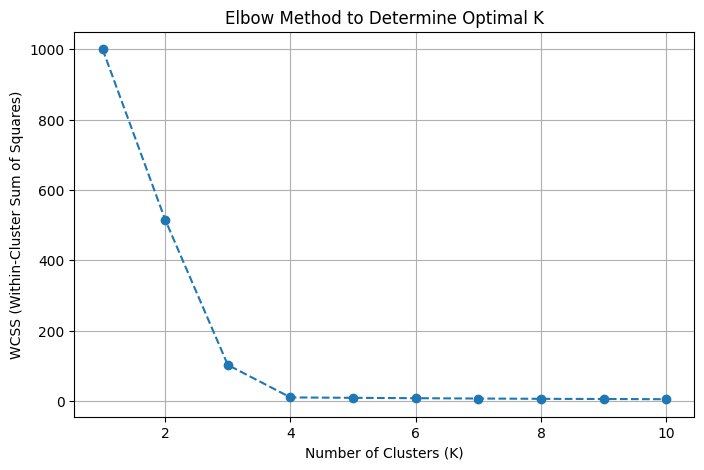

In [ ]:
# 2. Scale the features to ensure equal importance during distance calculations
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df)

# 3. Use the Elbow Method to determine the optimal number of clusters (K)
wcss = []
for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, init='k-means++', max_iter=300, n_init=10, random_state=42)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

# Plotting the Elbow Method results
plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss, marker='o', linestyle='--')
plt.title('Elbow Method to Determine Optimal K')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS (Within-Cluster Sum of Squares)')
plt.grid(True)
plt.show()

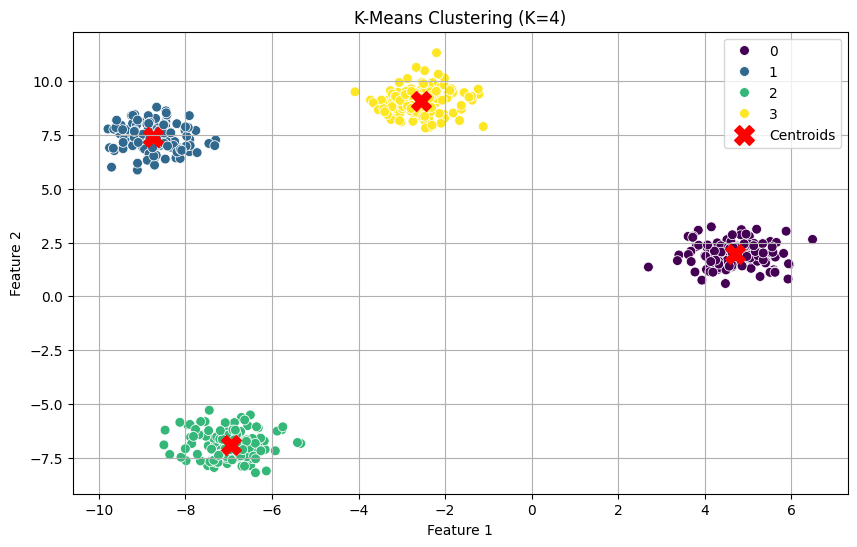

In [ ]:
# 4. Apply K-Means with the chosen number of clusters (K=4)
optimal_k = 4
kmeans = KMeans(n_clusters=optimal_k, init='k-means++', max_iter=300, n_init=10, random_state=42)
df['Cluster'] = kmeans.fit_predict(X_scaled)

# 5. Visualize the resulting clusters
plt.figure(figsize=(10, 6))
sns.scatterplot(
    x='Feature_1',
    y='Feature_2',
    hue='Cluster',
    palette='viridis',
    data=df,
    legend='full',
    s=50
)

# Plot the cluster centers (reconstructed back to the original scale)
centers = scaler.inverse_transform(kmeans.cluster_centers_)
plt.scatter(
    centers[:, 0],
    centers[:, 1],
    s=200,
    c='red',
    label='Centroids',
    marker='X'
)

plt.title(f'K-Means Clustering (K={optimal_k})')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.legend()
plt.grid(True)
plt.show()